In [1]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

Load the dataset from Kaggle.

In [2]:
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "muhammadishahrukh/nvidia-historical-stock-data",
    "nvda_stock_clean.csv",
)

df.head()

100%|██████████| 1.60M/1.60M [00:00<00:00, 1.82MB/s]


,date,ticker,open,high,low,close,volume,daily_return_pct,log_return,intraday_return_pct,daily_range_pct,overnight_gap_pct,sma_20,sma_50,volatility_20_pct,volume_sma_20,drawdown_pct,year,month,day_of_week
0,1999-01-22,NVDA,0.040018,0.044663,0.035492,0.037517,2714688000,NaN,NaN,-6.249138,22.916564,NaN,NaN,NaN,NaN,NaN,0.000000,1999,1,Friday
1,1999-01-25,NVDA,0.040494,0.041923,0.037517,0.041448,510480000,10.476402,0.099632,2.353687,10.880707,7.935928,NaN,NaN,NaN,NaN,0.000000,1999,1,Monday
2,1999-01-26,NVDA,0.041923,0.042757,0.037636,0.038231,343200000,-7.759382,-0.080770,-8.805878,12.216088,1.147548,NaN,NaN,NaN,NaN,-7.759382,1999,1,Tuesday
3,1999-01-27,NVDA,0.038350,0.039303,0.036206,0.038113,244368000,-0.311020,-0.003115,-0.620124,8.075938,0.311032,NaN,NaN,NaN,NaN,-8.046269,1999,1,Wednesday
4,1999-01-28,NVDA,0.038113,0.038350,0.037755,0.037993,227520000,-0.314385,-0.003149,-0.314397,1.562383,0.000012,NaN,NaN,NaN,NaN,-8.335358,1999,1,Thursday


In [7]:
df.shape

(6958, 20)

In [9]:
df.dtypes

date                    object
ticker                  object
open                   float64
high                   float64
low                    float64
close                  float64
volume                   int64
daily_return_pct       float64
log_return             float64
intraday_return_pct    float64
daily_range_pct        float64
overnight_gap_pct      float64
sma_20                 float64
sma_50                 float64
volatility_20_pct      float64
volume_sma_20          float64
drawdown_pct           float64
year                     int64
month                    int64
day_of_week             object
dtype: object

In [8]:
df.isna().sum()

date                    0
ticker                  0
open                    0
high                    0
low                     0
close                   0
volume                  0
daily_return_pct        1
log_return              1
intraday_return_pct     0
daily_range_pct         0
overnight_gap_pct       1
sma_20                 19
sma_50                 49
volatility_20_pct      20
volume_sma_20          19
drawdown_pct            0
year                    0
month                   0
day_of_week             0
dtype: int64

In this case, the target variable is the closing price of the assets.

<Axes: xlabel='close', ylabel='Count'>

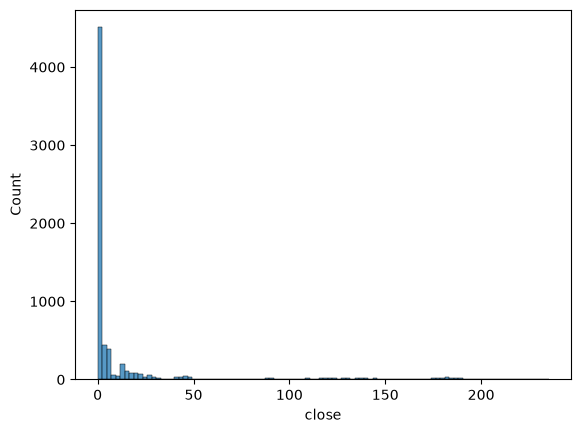

In [15]:
sns.histplot(data=df.close, bins=100)

<Axes: xlabel='close', ylabel='Count'>

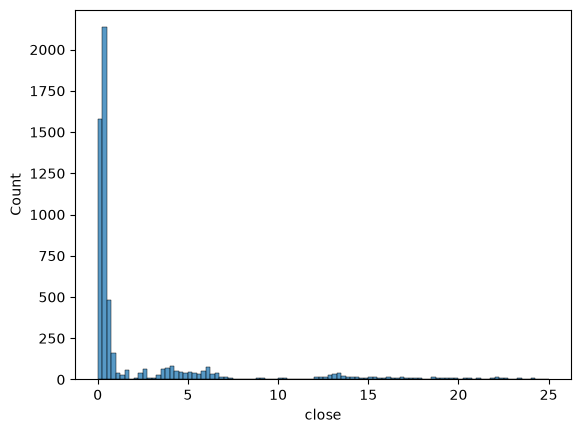

In [16]:
sns.histplot(data=df.close, bins=100, binrange=(0, 25))

<Axes: xlabel='close', ylabel='Count'>

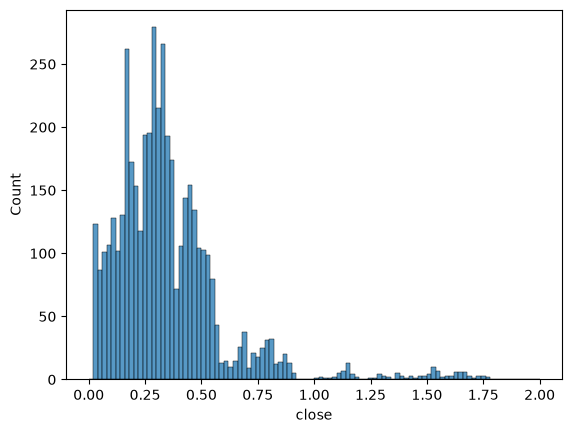

In [17]:
sns.histplot(data=df.close, bins=100, binrange=(0, 2))

As we can see, the most frequent values for the closing price lie in the (0, 1) interval.

Now, let's clean the dataset to make more exploratory data anallysis.

In [3]:
# These variables have only one missing value, so we can fill them with 0.
# Note these variables correspond to a variation regarding previous trading sessions,
# and the Nan value corresponds to the first trading session in the dataset, which makes sense.
for var in ["daily_return_pct", "log_return", "overnight_gap_pct"]:
    df[var] = df[var].fillna(0)

#As for the other variables, we can fill them with their average value.
for var in ["sma_20", "sma_50", "volatility_20_pct", "volume_sma_20"]:
    avr = df[var].mean()
    df[var] = df[var].fillna(avr)

Let's make some feature importance. The "date" is just the identifying label for each row, and "ticker" has a unique value (the brand's name). So they won't be used to train a model.

In [22]:
print(df.ticker.value_counts())

ticker
NVDA    6958
Name: count, dtype: int64


Regarding the remaining variables, many of them are functions of others. Concretely,

daily_return_pct, 
log_return, 
daily_range_pct, 
intraday_return_pct, 
overnight_gap_pct, 
sma_20, 
sma_50, 
volatility_20_pct, 
volume_sma_20, 
drawdown_pct,

are directly computed from the following variables:

open, 
high, 
low, 
close, 
volume,
day_of_the_week,
month.

This means, the only fully independent variables are the openning, closing, highest and lowest prices of the assets in the date, the trading volume, and, maybe less determinant, the day of the week and month. However, we should not hurry up to discard the other variables, since some of them contain information about the recent time evolution of the assets. This is, they are not only functions of the variables for the corresponding date, but they involve data from previous time periods, somehow containing memory information. We can discard the variables that are explicit functions of the mentioned independent variables for the same date, since they do not provide additional information. Only intraday_return_pct fulfills this description. To test the relevance of the other variables, I train a decision tree regressor including and then excluding them and compare the RMSE score.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import root_mean_squared_error
from sklearn.ensemble import RandomForestRegressor